# Post-processing workflow for gear trains, camtrains and drivelines (OpenModelica + Python)

`mbspost.py` turns any OpenModelica result built from the `GearMeshBenchmark` components into forces, torsional dynamics, modes and a report. It recognises the components by their variables, so the same script works for the benchmark, a camtrain or a driveline, whatever the instance names.

```
 1. MODEL          Modelica: assemble components, expose the parameters you want to vary at top level
       |
 2. RUN            OMRunner: compile once  ->  simulate many times with -override (no recompiling)
       |           (or simulate in OMEdit and load the .mat file)
 3. DISCOVER       System(res): finds every GearMesh2D, bearing, support, torsion element, body, load
       |
 4. METRICS        report(window / revolutions): one metric row per component, steady-state window
       |
 5. SIGNALS        time plots, orbits, ORDER spectra (resampled on the crank/driver angle)
       |
 6. MODES          linearise at a loaded instant -> eigenfrequencies, damping, energy per DOF, Campbell
       |
 7. COMPARE        parameter sweeps -> metric trends; HTML report + CSV for documentation
```

The notebook goes through the workflow on three models: Stage 1 (gear pair), Stage 2 (shaft and bearing) and `GearTrain3`, a small camtrain demo. It then shows how to extend the script and lists every metric.

In [1]:
import os, warnings
import numpy as np, matplotlib.pyplot as plt, pandas as pd
import mbspost as mp
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'font.size': 9})
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
MO = os.path.join('..', 'openmodelica', 'GearMeshBenchmark.mo')
# omc is searched in: OMC_PATH env variable, PATH, common install folders. Set it here if needed:
# os.environ['OMC_PATH'] = '/opt/openmodelica/bin/omc'
print('omc:', mp.OMRunner(MO, 'GearMeshBenchmark.Examples.Stage1').omc)

omc: /opt/om/bin/omc


## 1. Stage 1: gear pair, the basic workflow

`OMRunner.build()` compiles once (about 2 s). `simulate()` then runs the executable, about 0.1 s for Stage 1. Overrides change top-level parameters without recompiling.

In [2]:
r1 = mp.OMRunner(MO, 'GearMeshBenchmark.Examples.Stage1')
r1.build()
res1 = r1.simulate()
print(res1)
S1 = mp.System(res1)
print(S1.summary())

OMResult(GearMeshBenchmark.Examples.Stage1_res.mat: 185 variables, 24064 samples, t = 0..0.024 s)
8 components, reference = driver.frame.phi
gear1                        Body                     (body)
gear2                        Body                     (body)
mesh                         GearMesh2D               (gear)
drag                         ConstantTorque           (load)
driver                       ConstantSpeed            (source)
support1                     SpringDamper2D           (support)
support2                     SpringDamper2D           (support)
driveSpring                  TorsionSpringDamper      (torsion)


In [3]:
rep1 = S1.report()                      # whole run (the start-up impacts ARE the event of interest here)
rep1.table('GearMesh2D').T

,mesh
type,GearMesh2D
F_normal_mean_N,138.3
F_normal_max_N,8910
F_normal_min_N,-9462
F_normal_pp_N,1.837e+04
F_normal_rms_dyn_N,1248
F_tooth_max_N,9462
F_A_max_N,8910
F_B_max_N,9462
dyn_factor_Kv,68.43


**Reading the gear-mesh metrics**
* **Dynamic factor.** Peak tooth force 9 460 N (side B, first impact) against a mean normal force of 138 N gives a dynamic factor `dyn_factor_Kv` of about 68: the start-up rattle dominates.
* **Contact counts.** `impacts_A/B` counts contact onsets per flank. `flank_changes` counts A→B or B→A changes through a separation, i.e. load reversals.
* **Free play.** `free_play_max_um` is the largest gap seen. `penetration_max_um` is the largest tooth deflection.
* **DTE.** `DTE_pp_um` is the dynamic transmission error along the line of action, from the rotations only.
* **Damping.** `damping_energy_J` is the energy dissipated in the tooth damping.

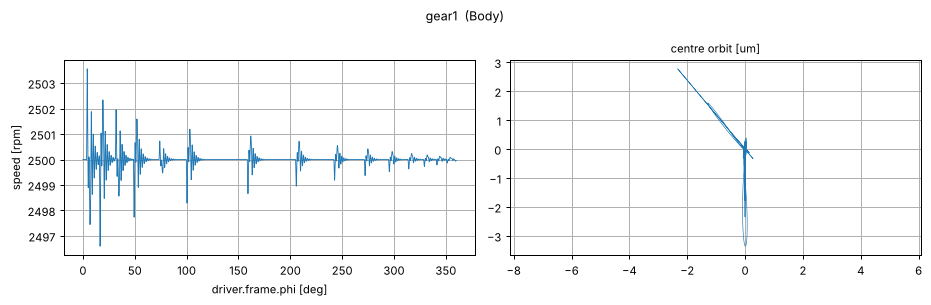

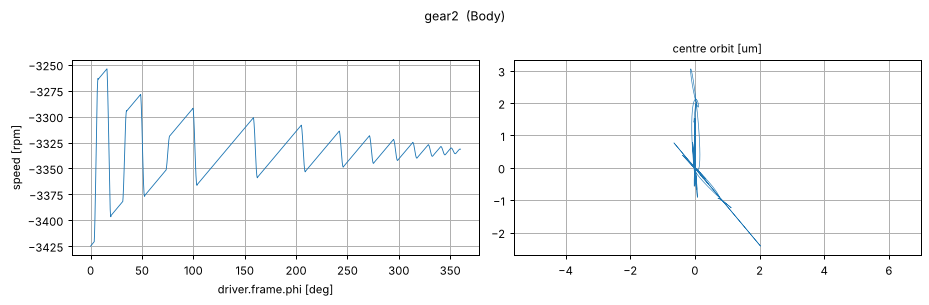

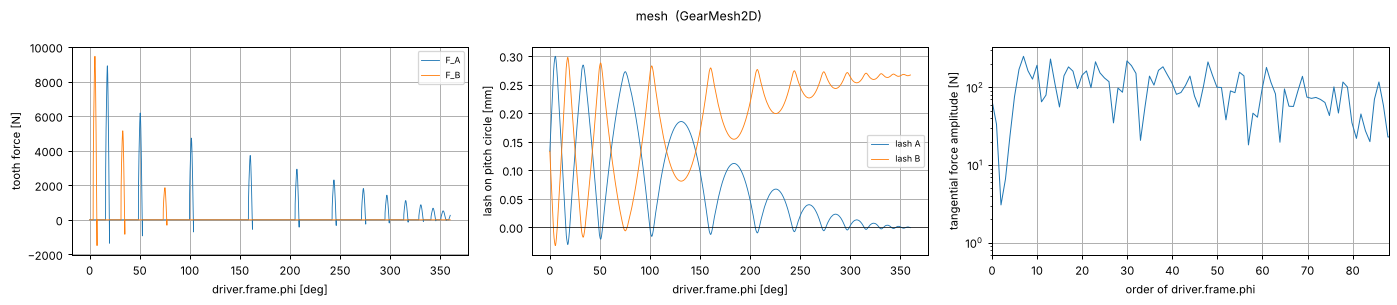

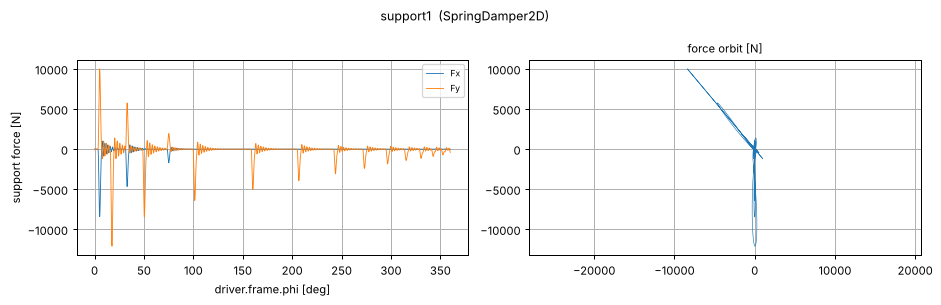

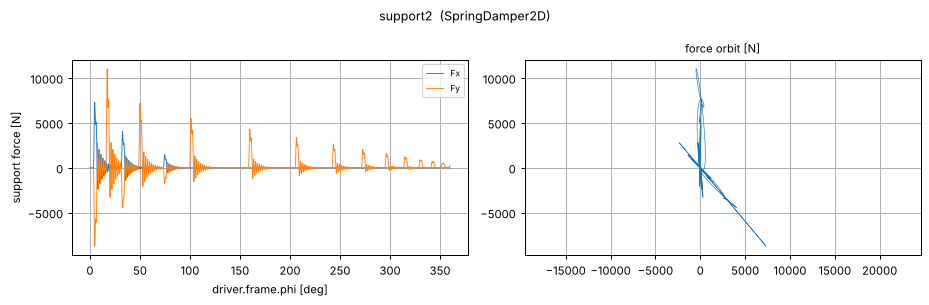

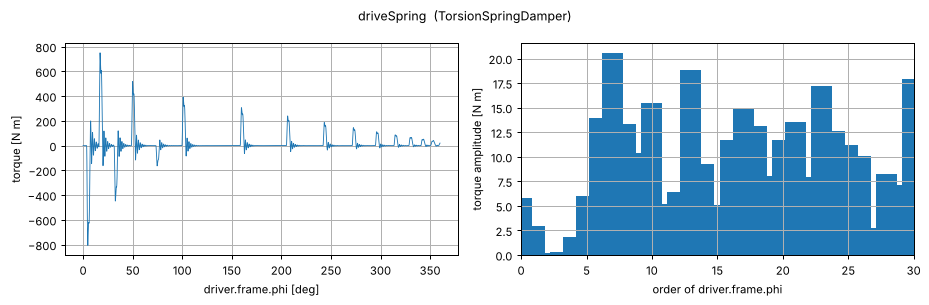

In [4]:
figs = rep1.figures()

In [5]:
rep1.table('SpringDamper2D').T     # bearing (support) reaction forces of both gears

,support1,support2
type,SpringDamper2D,SpringDamper2D
F_res_mean_N,489.8,555
F_res_max_N,1.307e+04,1.14e+04
F_res_min_N,0,0
F_res_pp_N,1.307e+04,1.14e+04
F_res_rms_dyn_N,1373,1320
Fx_mean_N,-70.9,70.9
Fx_max_N,1001,7326
Fx_min_N,-8400,-2344
Fx_pp_N,9401,9670


## 2. Stage 2: shaft, bearing with clearance, non-linear supports

The analysis window can be given in **reference revolutions**. Here it skips the first revolution of the driver.

In [6]:
r2 = mp.OMRunner(MO, 'GearMeshBenchmark.Examples.Stage2Calibrated')
r2.build()
S2 = mp.System(r2.simulate())
print(S2.summary())
rep2 = S2.report(revs=(1, None))
pd.concat([rep2.table('RadialBearingClearance').T, rep2.table('NonlinearSupport2D').T], axis=1)

13 components, reference = driver.frame.phi
bearing                      RadialBearingClearance   (bearing)
gear1                        Body                     (body)
gear2                        Body                     (body)
node8                        PointMass                (body)
node9                        PointMass                (body)
nodeM                        PointMass                (body)
mesh                         GearMesh2D               (gear)
load                         SineAngleTorque          (load)
driver                       ConstantSpeed            (source)
supBlock                     NonlinearSupport2D       (support)
supCase                      NonlinearSupport2D       (support)
support1                     SpringDamper2D           (support)
driveSpring                  TorsionSpringDamper      (torsion)


,bearing,supBlock,supCase
type,RadialBearingClearance,NonlinearSupport2D,NonlinearSupport2D
F_res_mean_N,127.2,69.86,67.36
F_res_max_N,957.4,631,502.2
F_res_min_N,0,0.04377,0.04264
F_res_pp_N,957.4,631,502.1
F_res_rms_dyn_N,170.1,95.26,87.78
Fx_mean_N,-37.27,18.63,18.65
Fx_max_N,427.9,391.2,394
Fx_min_N,-733.4,-408.7,-304.4
Fx_pp_N,1161,799.9,698.5


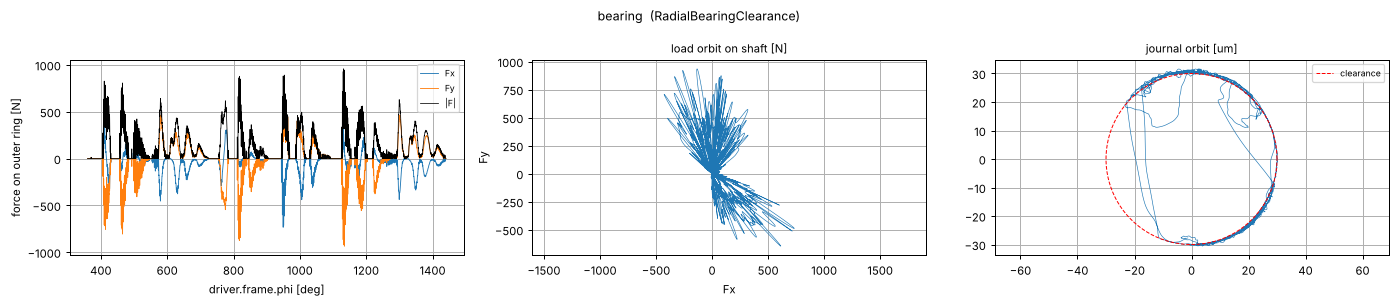

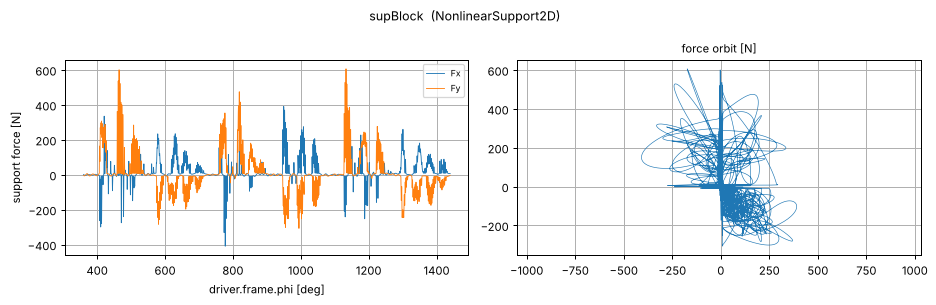

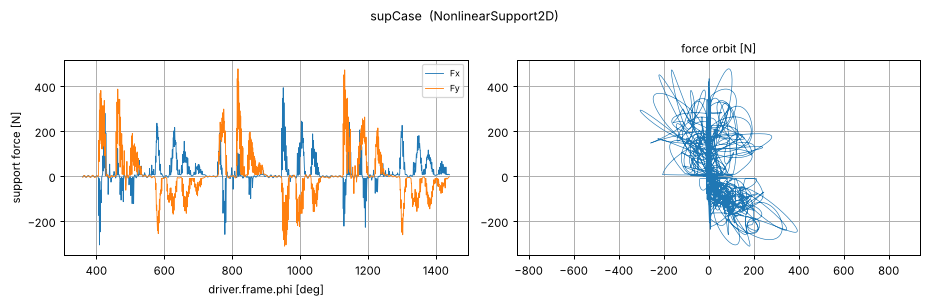

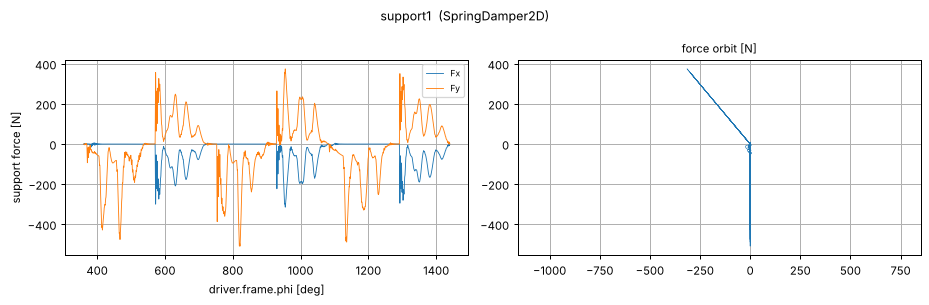

In [7]:
figs2 = rep2.figures(groups=['bearing', 'support'])

The **journal orbit** (right) shows the gear sliding around inside the 30 µm clearance circle. Points outside the circle are bearing contact, and their distance beyond it is the bearing deflection. The **load orbit** shows the direction and size of the force on the shaft. The Block/Case support forces are the reactions passed on to the housing, the numbers a housing or bolt designer needs.

## 3. Camtrain demo `GearTrain3`: torsional dynamics

| Component | Description |
| --- | --- |
| Crank gear | z = 20, driven at 6000 rpm through the crank-nose spring |
| Idler | z = 40, on a bearing with 10 µm clearance |
| Cam gear | z = 40, runs at half crank speed |
| Camshaft | elastic, 2·10⁴ N·m/rad |
| Cam torque | 3 N·m mean drag plus 15 N·m at the 2nd crank order |

The cam torque reverses sign, so the gears rattle: this is the classic camtrain problem.

In [8]:
r3 = mp.OMRunner(MO, 'GearMeshBenchmark.Examples.GearTrain3')
r3.build()
res3 = r3.simulate()
S3 = mp.System(res3)
print(S3.summary())
rep3 = S3.report(revs=(3, None))          # skip 3 crank revolutions of run-in

15 components, reference = driver.frame.phi
idlerBearing                 RadialBearingClearance   (bearing)
camGear                      Body                     (body)
camshaft                     Body                     (body)
crankGear                    Body                     (body)
idler                        Body                     (body)
mesh1                        GearMesh2D               (gear)
mesh2                        GearMesh2D               (gear)
camDrag                      ConstantTorque           (load)
camTorque                    SineAngleTorque          (load)
driver                       ConstantSpeed            (source)
camSupport                   SpringDamper2D           (support)
camshaftSupport              SpringDamper2D           (support)
crankSupport                 SpringDamper2D           (support)
camshaftTorsion              TorsionSpringDamper      (torsion)
crankSpring                  TorsionSpringDamper      (torsion)


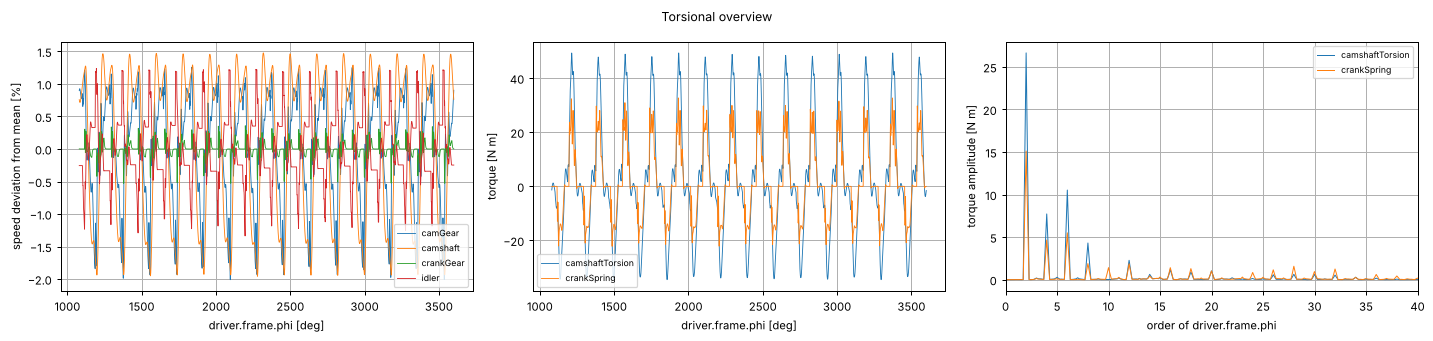

In [9]:
fig = rep3.torsional_overview()

**Torsional overview**
* **Left:** speed irregularity of every rotating body, in % of its mean speed.
* **Middle:** torque in every torsional element.
* **Right:** order spectrum of those torques, resampled on the crank angle so that order *n* means n times per crank revolution.

The excitation sits at orders 2, 4, 6 …: the 2nd-order cam torque plus its harmonics, which the rattle generates. Mesh-frequency content would appear at order 20 (crank teeth).

In [10]:
pd.concat([rep3.table('TorsionSpringDamper').T, rep3.table('Body').T], axis=1)

,camshaftTorsion,crankSpring,camGear,camshaft,crankGear,idler
type,TorsionSpringDamper,TorsionSpringDamper,Body,Body,Body,Body
T_mean_Nm,3,1.504,NaN,NaN,NaN,NaN
T_max_Nm,49.34,32.71,NaN,NaN,NaN,NaN
T_min_Nm,-34.51,-22.17,NaN,NaN,NaN,NaN
T_pp_Nm,83.85,54.88,NaN,NaN,NaN,NaN
T_rms_dyn_Nm,21.33,12.37,NaN,NaN,NaN,NaN
twist_mean_deg,0.008596,0.001724,NaN,NaN,NaN,NaN
twist_pp_deg,0.2402,0.06289,NaN,NaN,NaN,NaN
T_dyn_factor,16.44,21.75,NaN,NaN,NaN,NaN
dominant_order,1.999,1.999,NaN,NaN,NaN,NaN


In [11]:
rep3.table('GearMesh2D').T

,mesh1,mesh2
type,GearMesh2D,GearMesh2D
F_normal_mean_N,80.04,-79.82
F_normal_max_N,1696,898.6
F_normal_min_N,-1122,-1537
F_normal_pp_N,2818,2436
F_normal_rms_dyn_N,651.1,620.4
F_tooth_max_N,1696,1537
F_A_max_N,1696,898.6
F_B_max_N,1122,1537
dyn_factor_Kv,21.2,19.26


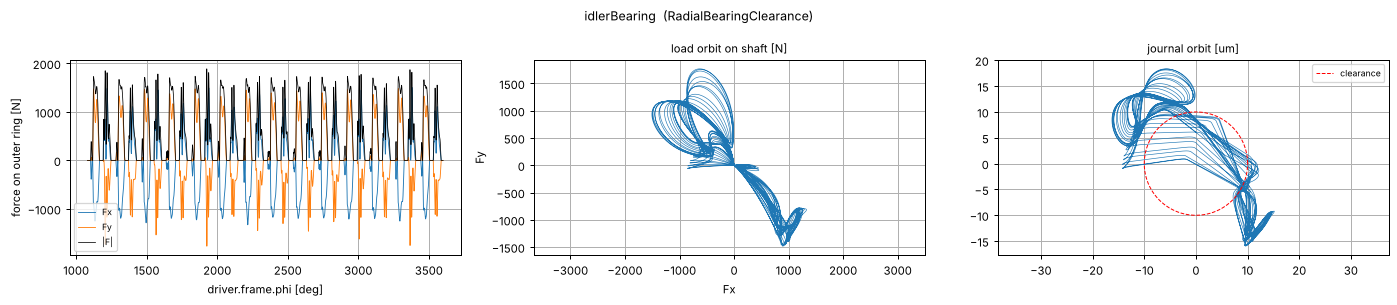

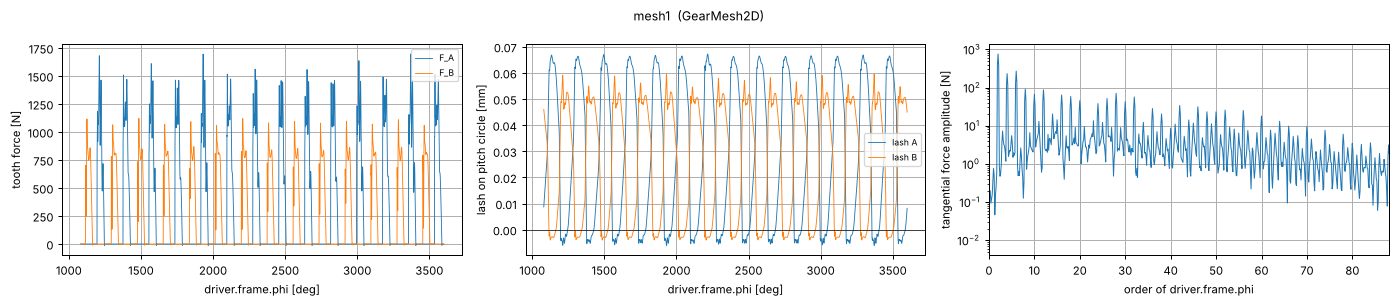

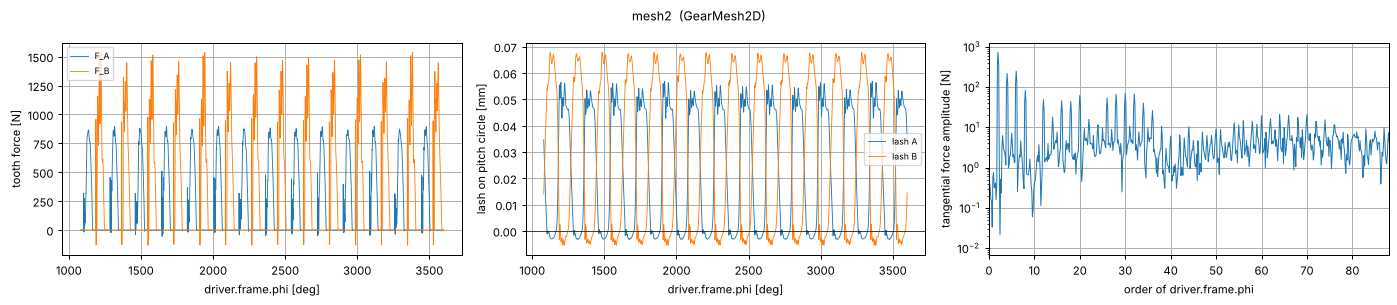

In [12]:
figs3 = rep3.figures(groups=['gear', 'bearing'])

## 4. Modes and Campbell diagram (linearised model)

`OMRunner.modes(t_lin)` simulates to `t_lin`, linearises there with OpenModelica, and turns the state matrix into modes:
* eigenfrequency and damping ratio;
* the kinetic-energy share of each degree of freedom, which tells torsional from lateral modes.

**Contacts are non-linear, so linearise in a loaded state.** Open contacts contribute no stiffness to the linear model, and `modes()` warns when a mesh or bearing is open at `t_lin`. The robust recipe sets the free play to almost zero **for the linearisation only**:
* backlash 0.1 µm: one flank stays closed. With exactly 0, both flanks touch and the mesh stiffness doubles.
* bearing clearance 0.

In [13]:
modes3 = r3.modes(0.05, overrides={'jn': 1e-7, 'clr_idler': 0})
print('contact state at t_lin:', modes3.contact_state)
modes3.table()

contact state at t_lin: {'mesh1': 'flank A', 'mesh2': 'flank B', 'idlerBearing': 'in contact'}


,f_Hz,zeta_pct,type,torsional_energy_pct,dominant_dofs
0,437.2,11.54,torsional,99.82,"camshaft.phi 97%, camGear.phi 2%, idler.phi 1%"
1,1570,22.81,torsional,86.16,"camGear.phi 43%, idler.phi 35%, idler.v 13%"
2,2179,2.784,lateral,32.13,"idler.u 57%, camGear.phi 18%, idler.phi 14%"
3,2994,12.04,lateral,25.65,"idler.v 45%, camGear.phi 18%, idler.u 16%"
4,3247,3.062,lateral,1.004e-33,"camshaft.v 97%, camshaft.u 3%, camGear.v 0%"
5,3247,3.062,lateral,2.652e-34,"camshaft.u 98%, camshaft.v 2%, camGear.u 0%"
6,3272,66.93,torsional,86.73,"crankGear.phi 70%, idler.phi 11%, idler.v 9%"
7,3932,16.68,lateral,30.98,"camGear.u 38%, idler.v 22%, crankGear.phi 13%"
8,3976,3.75,lateral,5.189e-20,"camGear.v 88%, camGear.u 12%, camGear.phi 0%"
9,8035,11.82,lateral,49.11,"idler.phi 29%, camGear.phi 19%, crankGear.v 16%"


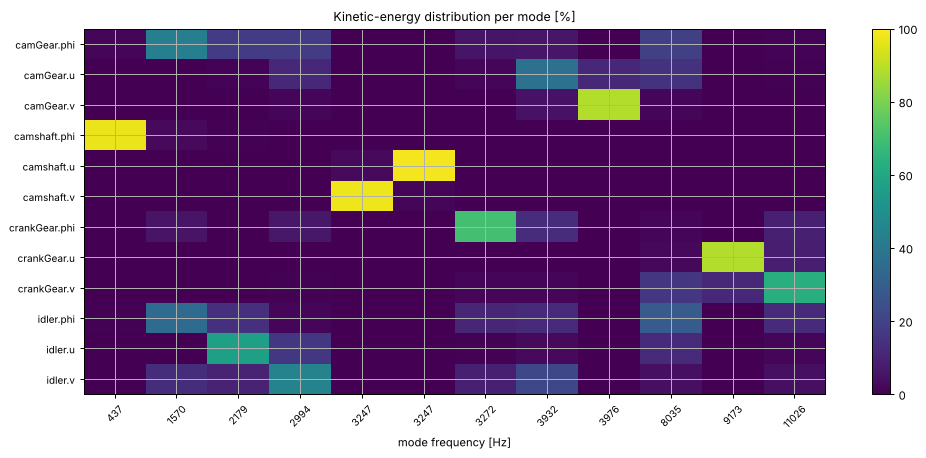

In [14]:
fig = modes3.plot_energy()

,order,f_Hz,mode_type,rpm_resonance
2,20,437.2,torsional,1312
1,6,437.2,torsional,4372
3,20,1570,torsional,4711
0,4,437.2,torsional,6558


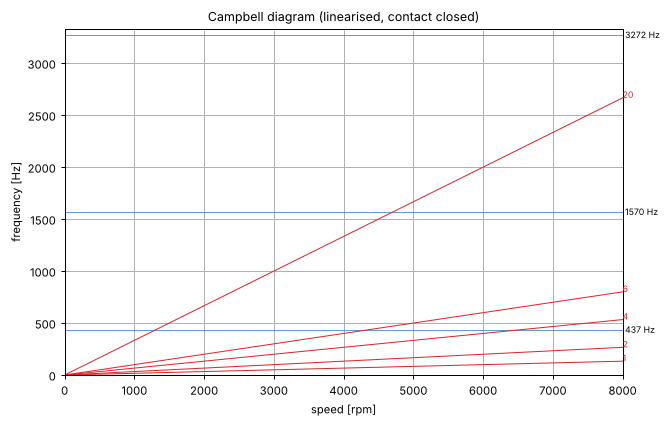

In [15]:
fig, res_tab = mp.campbell(modes3, orders=[1, 2, 4, 6, 20], rpm=(0, 8000), only='torsional')
res_tab

**Reading the Campbell diagram.** Horizontal lines are torsional eigenfrequencies; the sloped lines are excitation orders, f = order × rpm / 60. Each crossing inside the speed range is a potential resonance, listed in the table.

For this demo the camshaft torsion mode (about 440 Hz) is crossed by:
* order 6 at about 4 400 rpm;
* order 4 at about 6 600 rpm, just above the simulated 6000 rpm;
* the mesh order 20 at about 1 300 rpm.

## 5. Parameter sweep: effect of backlash

`mp.sweep()` re-runs the compiled model for several values of a top-level parameter and collects the metrics side by side (about 0.4 s per run).

In [16]:
jn_values = [0.01e-3, 0.03e-3, 0.05e-3, 0.08e-3, 0.12e-3]
keys = [('mesh1', 'F_tooth_max_N'), ('mesh2', 'F_tooth_max_N'), ('mesh1', 'impacts_A'), ('mesh1', 'impacts_B'),
        ('mesh2', 'impacts_A'), ('mesh2', 'impacts_B'), ('mesh1', 'flank_changes'),
        ('idlerBearing', 'F_res_max_N'), ('camshaftTorsion', 'T_pp_Nm'), ('camGear', 'irregularity_pct')]
tab, reps = mp.sweep(r3, 'jn', jn_values, revs=(3, None), keys=keys)
tab.columns = [f'{v*1e3:g} mm' for v in jn_values]
tab

0.01 mm  0.03 mm  0.05 mm  0.08 mm  0.12 mm
idlerBearing    F_res_max_N          1879     1667     1890     2930     3922
camGear         irregularity_pct    2.218    2.576    3.262    4.288    5.532
mesh1           F_tooth_max_N        1357     1464     1696     2268     2671
                impacts_A              16       14       14       14       14
                impacts_B              19       15       14       16       14
                flank_changes          27       27       27       27       27
mesh2           F_tooth_max_N        1162     1317     1537     2047     2446
                impacts_A              28       34       38       50       41
                impacts_B              29       29       28       34       33
camshaftTorsion T_pp_Nm             68.36       73    83.85    102.1    126.1

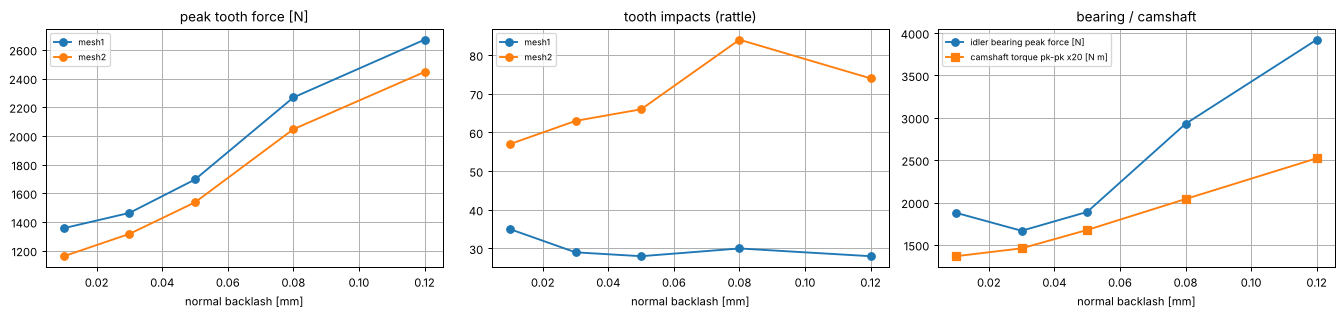

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
x = np.array(jn_values)*1e3
for comp in ('mesh1', 'mesh2'):
    axs[0].plot(x, tab.loc[(comp, 'F_tooth_max_N')], 'o-', label=comp)
    axs[1].plot(x, tab.loc[(comp, 'impacts_A')] + tab.loc[(comp, 'impacts_B')], 'o-', label=comp)
axs[2].plot(x, tab.loc[('idlerBearing', 'F_res_max_N')], 'o-', label='idler bearing peak force [N]')
axs[2].plot(x, tab.loc[('camshaftTorsion', 'T_pp_Nm')]*20, 's-', label='camshaft torque pk-pk x20 [N m]')
for a, t in zip(axs, ['peak tooth force [N]', 'tooth impacts (rattle)', 'bearing / camshaft']):
    a.set_xlabel('normal backlash [mm]'); a.set_title(t); a.legend(fontsize=7)
plt.tight_layout()

Going from 0.01 to 0.12 mm backlash roughly doubles the peak tooth force (mesh1: 1 360 → 2 670 N) and the idler-bearing peak force (1 880 → 3 920 N). The camshaft torque peak-to-peak rises by 85 %. `flank_changes` stays at 27 for every backlash: it counts the torque reversals, two per cam-torque cycle, while `impacts_A/B` count the extra bounces.

## 6. HTML report (for documentation and sharing)

`to_html()` writes one self-contained file: the components found, every metric table, the system overviews, the modes and every component figure. `to_csv()` writes one CSV per component type.

In [18]:
os.makedirs('example_reports', exist_ok=True)
fig_c, _ = mp.campbell(modes3, orders=[1, 2, 4, 6, 20], rpm=(0, 8000), only='torsional')
rep3.to_html('example_reports/report_GearTrain3.html', title='GearTrain3 (camtrain demo), 6000 rpm',
             modes=modes3, extra_figs=[fig_c])
rep3.to_csv('example_reports/GearTrain3_csv')
rep2.to_html('example_reports/report_Stage2Calibrated.html', title='Stage 2 calibrated')
print(os.listdir('example_reports'))

['report_Stage2Calibrated.html', 'report_GearTrain3.html', 'GearTrain3_csv']


## 7. Results simulated in OMEdit

Nothing above depends on running OpenModelica from Python. Simulate in OMEdit, which writes `<Model>_res.mat` into its working directory, and load that file:

```python
res = mp.OMResult('/path/to/OMEdit/work/GearMeshBenchmark.Examples.GearTrain3_res.mat')
rep = mp.System(res).report(revs=(3, None))
```

Command-line version of the whole workflow:

```
python run_postprocessing.py --mat <result.mat> --revs 3 --out my_report
python run_postprocessing.py --mo ../openmodelica/GearMeshBenchmark.mo --model GearMeshBenchmark.Examples.GearTrain3 \
       --set jn=0.08e-3 --revs 3 --modes 0.05 --lin-set jn=1e-7 clr_idler=0 --orders 1 2 4 20 --rpm 0 8000
```

## 8. Extending the script for new components or metrics

Each component type is registered with three things: a **signature** (variable names that must exist under the instance), a **metrics function** and optionally a **plot function**. A new Modelica component, for example a cam–follower contact with variables `Fc` and `h`, only needs one `register()` call. Below, a custom metric is added to the existing gear mesh.

In [19]:
def gear_metrics_plus(c, ctx):
    out = mp.gear_metrics(c, ctx)
    revs = (ctx.ref_angle[ctx.mask][-1] - ctx.ref_angle[ctx.mask][0])/(2*np.pi) if ctx.ref_angle is not None else np.nan
    out['impacts_per_rev'] = (out['impacts_A'] + out['impacts_B'])/revs
    return out

old = next(t for t in mp.REGISTRY if t.name == 'GearMesh2D')
mp.register(mp.ComponentType('GearMesh2D', old.signature, metrics=gear_metrics_plus, plot=old.plot,
                             nplots=old.nplots, group='gear', priority=old.priority))
mp.System(res3).report(revs=(3, None)).table('GearMesh2D').T.loc[['impacts_A', 'impacts_B', 'impacts_per_rev']]

,mesh1,mesh2
impacts_A,14,38
impacts_B,14,28
impacts_per_rev,4,9.429


Template for a new component type:

```python
def cam_metrics(c, ctx):                     # c['Fc'] -> time series of instance.Fc, c.p('k') -> parameter
    m, t = ctx.mask, ctx.t[ctx.mask]
    out = mp._stats(c['Fc'][m], t, 'F_contact', 'N')
    out['lift_off_pct'] = 100*mp._frac(c['Fc'][m] <= 0, t)
    return out

mp.register(mp.ComponentType('CamFollower', signature=('Fc', 'h', 'k'), metrics=cam_metrics,
                             group='gear', priority=95))
```

## 9. Modelling rules that keep post-processing robust

| Rule | Why |
| --- | --- |
| Build systems from these components and give instances meaningful names | discovery works at any nesting depth; the names appear in the report |
| Expose every parameter you want to vary or sweep as a **top-level parameter** | OpenModelica cannot override parameters bound to other parameters (`mesh1.jn` when it is `jn=jn`). `OMRunner` raises an error instead of silently ignoring the override |
| Never put `der(...)` inside an `if`-expression whose condition contains a parameter; compute the derivative in its own variable first | otherwise OpenModelica freezes that parameter at compile time (this happened with the bearing clearance and is fixed in the library) |
| Keep `stateSelect=StateSelect.prefer` on the body coordinates | the linearised states are then the physical DOFs, so the modal energy map is complete |
| One `ConstantSpeed` source, or pass `reference='crankGear.phi'` | the x-axis and the order analysis use this angle |
| Do not filter result variables (or keep `*.FA`, `*.Fx`, `*.frame*`, parameters) | metrics need the component variables and parameters |

## 10. Metric glossary

| Component | Metric | Meaning |
| --- | --- | --- |
| GearMesh2D | `F_normal_*_N` | signed normal force F_A − F_B (A = drive flank positive): mean, max, min, peak-to-peak, RMS of the dynamic part |
| | `F_tooth_max_N`, `F_A_max_N`, `F_B_max_N` | peak tooth force (either flank / per flank) |
| | `dyn_factor_Kv` | peak tooth force / mean normal force |
| | `contact_A_pct`, `contact_B_pct`, `separated_pct`, `double_flank_pct` | share of time in each contact state |
| | `impacts_A/B`, `flank_changes` | contact onsets per flank, flank changes through separation (rattle) |
| | `penetration_max_um`, `free_play_max_um`, `backlash_n_um` | largest tooth deflection, largest gap, nominal backlash |
| | `DTE_pp_um`, `DTE_rms_dyn_um` | dynamic transmission error r_b1·φ₁ + r_b2·φ₂ (line of action) |
| | `damping_energy_J`, `damping_power_mean_W` | energy dissipated by the tooth damping |
| RadialBearingClearance | `F_res_*_N`, `Fx_*`, `Fy_*` | resultant and component forces on the outer ring |
| | `F_res_max_dir_deg` | direction of the peak load on the shaft |
| | `eccentricity_max_um`, `clearance_use_max_pct`, `penetration_max_um` | journal travel, as % of the clearance, deflection beyond it |
| | `contact_pct`, `impacts` | share of time in contact, number of contact onsets |
| | `friction_power_mean_W` | mean friction power loss |
| NonlinearSupport2D, SpringDamper2D | `F_res_*_N`, `Fx_*`, `Fy_*` | support (reaction) forces |
| | `disp_*_um` | support deflection |
| TorsionSpringDamper | `T_*_Nm`, `T_dyn_factor` | torque statistics; peak / mean |
| | `twist_mean_deg`, `twist_pp_deg` | static and dynamic twist |
| | `dominant_order`, `dominant_order_amp_Nm` | largest order component of the torque |
| Body, PointMass | `speed_mean_rpm`, `speed_pp_rpm`, `irregularity_pct` | mean speed, fluctuation, (ω_max − ω_min) / ω_mean |
| | `ang_acc_max_rad_s2`, `inertia_torque_max_Nm` | peak angular acceleration, J·α |
| | `disp_res_max_um`, `disp_x/y_pp_um` | centre motion |
| Modes | `f_Hz`, `zeta_pct`, `type`, `torsional_energy_pct`, `dominant_dofs` | eigenfrequency, damping, torsional/lateral classification, energy distribution |